In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.font_manager import FontProperties

from dotenv import dotenv_values

from hm3d_utils.plotting import zoom_umap

plt.rcParams["pdf.fonttype"] = 42

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_05" 
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 

In [3]:
adata = sc.read_h5ad(SC_ADATA_FP)

In [4]:
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata, base=2)

## UMAP NN only

In [5]:
# old ones from before 

l1_colors = {
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}

scattersize = 0.075

In [6]:
for i in [1,2]:

    adata.obs[f"L{i}_NN"] = adata.obs[f"L{i}_descr"].astype(str).copy()
    adata.obs.loc[~adata.obs[f"L{i}_descr"].str.contains("NN"), f"L{i}_NN"] = np.nan 
    adata.obs[f"L{i}_NN"] = adata.obs[f"L{i}_NN"].astype("category")

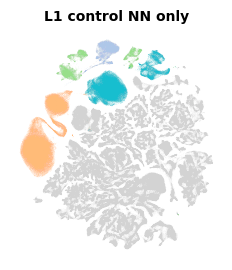

In [7]:

fig, ax = plt.subplots(figsize=(3, 3), ) 

# Then plot using the custom palette
sc.pl.umap(
    adata,
    color="L1_NN",
    ax=ax,
    show=False,
    s=scattersize,
    palette = l1_colors,
    legend_loc=None,
)

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title(f"L1 control NN only", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR / f"5d_umap_l1_control_NN_only.pdf", format="pdf", dpi=300, bbox_inches="tight") 

## Astrocytes

In [ ]:
def plot_and_save_GE_ctrl_only(adata, genes_to_plot_list, plot_save_dir, save_string_suffix=None, scattersize=15, vmax=None):

    for gene in genes_to_plot_list:

        # Create high-resolution figure and axis
        fig, ax = plt.subplots(figsize=(3, 3)) 

        # Plot with Scanpy onto the given axis
        sc.pl.umap(
            adata[adata.obs.IsControl], 
            color=gene,
            ax=ax,
            show=False,
            size=scattersize,
            vmax=vmax
        )

        # --- Rasterize the scatter plot points ---
        for artist in ax.collections:
            artist.set_rasterized(True)

        # Remove default title, borders, ticks, and labels
        ax.set_title(gene, fontsize=10, fontweight="bold")
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_aspect('equal')

        # Modify the colorbar
        for cax in fig.axes:
            if cax != ax:
                # Shrink the colorbar by modifying its position
                pos = cax.get_position()
                cax.set_position([
                    pos.x0 + 0,      # move right
                    pos.y0 + 0,       # move up
                    pos.width * 20,     # stretch horizontally
                    pos.height * 1#0.75  # shrink vertically
                ])

                # Set label and tick styles
                cax.set_ylabel("log1p(CP10K)", fontsize=8, fontweight='bold', labelpad=10)
                cax.tick_params(labelsize=8)
                for label in cax.get_yticklabels():
                    label.set_fontweight('bold')
                break



        # Save figure
        save_name = f"umap_{gene}_expr_C_only"
        if isinstance(save_string_suffix, str):
            save_name += save_string_suffix

        fig.savefig(
            Path(plot_save_dir) / f"{save_name}.pdf",
            dpi=300,
            format="pdf",
            bbox_inches="tight"
        )


In [9]:
astro = adata[adata.obs.L3_descr.str.contains("Astro")].copy()

In [ ]:
#plt.hist(astro.obsm["X_umap"][:, 1], bins=50)

In [11]:
# remove cells outside the main UMAP clusters
astro_mask = (astro.obsm["X_umap"][:, 0] > 4) & (astro.obsm["X_umap"][:, 0] < 13) & (
    astro.obsm["X_umap"][:, 1] > 6)


In [12]:
s=7

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


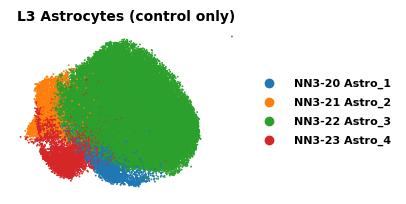

In [13]:
fig, ax = plt.subplots(figsize=(3, 3), ) 
# Pass the axis to Scanpy
sc.pl.umap(astro[astro_mask], color="L3_descr", ax=ax, s=s, show=False, )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L3 Astrocytes (control only)", fontweight="bold", fontsize=10)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')


# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(8)
        text.set_fontweight("bold")

fig.canvas.draw()

plt.savefig(OUTDIR / "5b_umap_L3_Astro_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

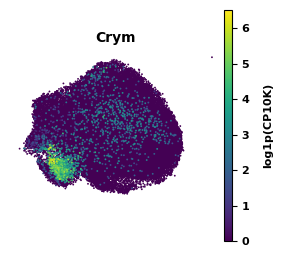

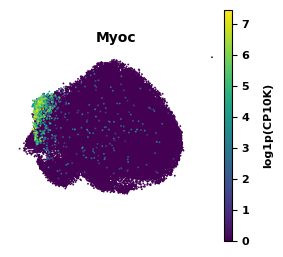

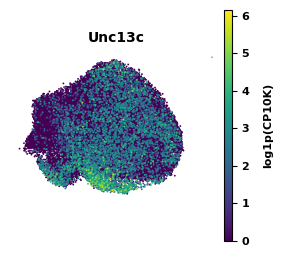

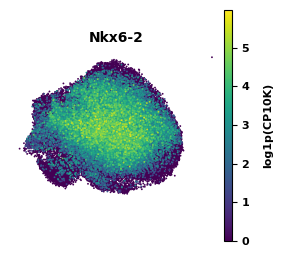

In [15]:
genes_to_plot_list = ["Crym", "Myoc", "Unc13c", "Nkx6-2" ]
save_string_suffix = "astro"


plot_and_save_GE_ctrl_only(
    astro[astro_mask], 
    genes_to_plot_list, 
    f"{str(OUTDIR)}/", 
    save_string_suffix=save_string_suffix, 
    scattersize=s, 
    vmax=None)

## ENDO

In [16]:
endo = adata[adata.obs.L3_descr.str.contains("Endo")].copy()

In [17]:
#plt.hist(endo.obsm["X_umap"][:, 0], bins=50)

In [18]:
# remove cells outside the main UMAP clusters
endo_mask = (endo.obsm["X_umap"][:, 1] > 10) & (endo.obsm["X_umap"][:, 0] < 5)

In [19]:
s = 20

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


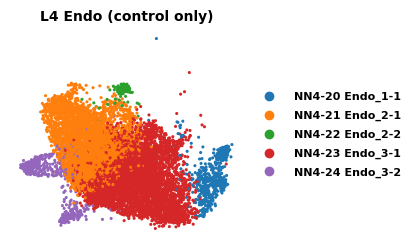

In [20]:
for L in range(4,5):

    # Create a high-DPI figure and axis
    fig, ax = plt.subplots(figsize=(3, 3), ) 

    # Pass the axis to Scanpy
    sc.pl.umap(endo[endo_mask], color=f"L{L}_descr", ax=ax, s=s, show=False,  )

    # Rasterize only the scatter points (not text)
    for coll in ax.collections:
        coll.set_rasterized(True)

    # Customize: remove title, borders, ticks, labels
    ax.set_title(f"L{L} Endo (control only)", fontweight="bold", fontsize=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect('equal')


    # --- Customize legend ---
    leg = ax.get_legend()
    if leg is not None:
        # Change font size and weight
        for text in leg.get_texts():
            text.set_fontsize(8)
            text.set_fontweight("bold")
        

    fig.canvas.draw()

    plt.savefig(OUTDIR / f"5g_umap_L{L}_Endo_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

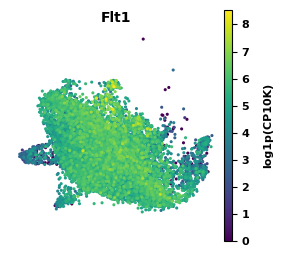

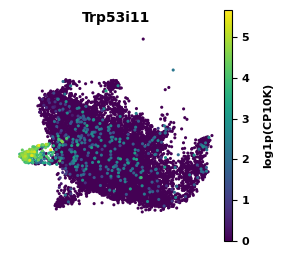

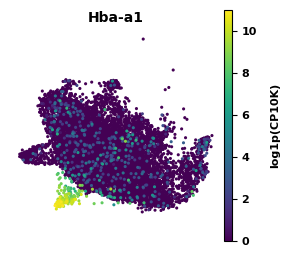

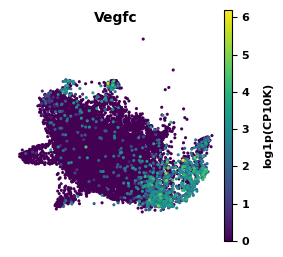

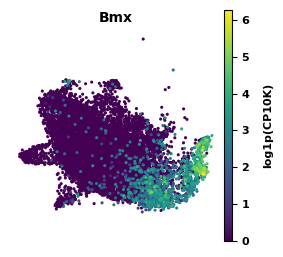

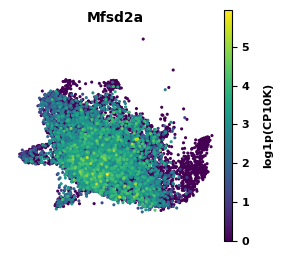

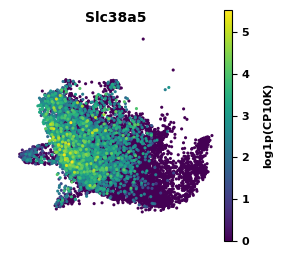

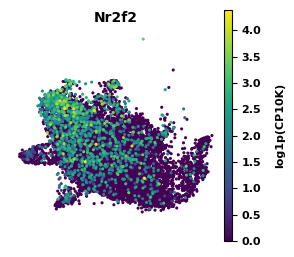

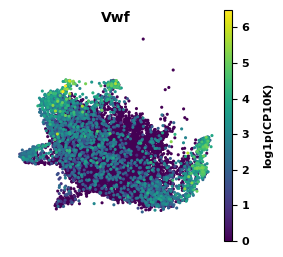

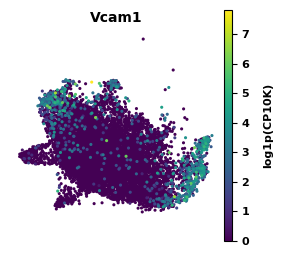

In [21]:
genes_to_plot_list = [#"Cldn5",
                     "Flt1", #EC
                    "Trp53i11", 
                    #"Apln", # angiogenic
                    "Hba-a1", 
                    #"Hbb-bs", 
                    "Vegfc", "Bmx", # arterial
                    "Mfsd2a", #"Tfrc", # capillary
                    "Slc38a5", "Nr2f2", # venous
                    "Vwf", "Vcam1" #arterial and venous
                        ]
save_string_suffix = "endo"

plot_and_save_GE_ctrl_only(
    endo[endo_mask], 
    genes_to_plot_list, 
    f"{str(OUTDIR)}/", 
    save_string_suffix=save_string_suffix, 
    scattersize=s, 
    vmax=None)

## SMC

In [22]:
smc = adata[adata.obs.L3_descr.str.contains("SMC")].copy()

In [23]:
#plt.hist(smc.obsm["X_umap"][:, 1], bins=50)

In [24]:
# remove cells outside the main UMAP clusters
smc_mask = (smc.obsm["X_umap"][:, 1] > 14)

In [25]:
s = 80

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


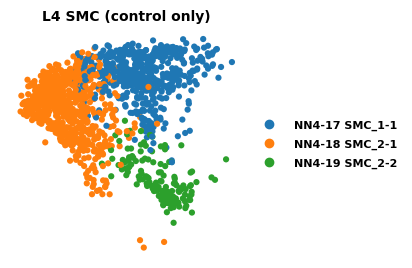

In [26]:
for L in range(4,5):

    # Create a high-DPI figure and axis
    fig, ax = plt.subplots(figsize=(3, 3), ) 

    # Pass the axis to Scanpy
    sc.pl.umap(smc[smc_mask], color=f"L{L}_descr", ax=ax, s=s, show=False,  )

    # Rasterize only the scatter points (not text)
    for coll in ax.collections:
        coll.set_rasterized(True)

    # Customize: remove title, borders, ticks, labels
    ax.set_title(f"L{L} SMC (control only)", fontweight="bold", fontsize=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect('equal')


    # --- Customize legend ---
    leg = ax.get_legend()
    if leg is not None:
        # Change font size and weight
        for text in leg.get_texts():
            text.set_fontsize(8)
            text.set_fontweight("bold")
        

    fig.canvas.draw()

    plt.savefig(OUTDIR / f"5h_umap_L{L}SMC_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

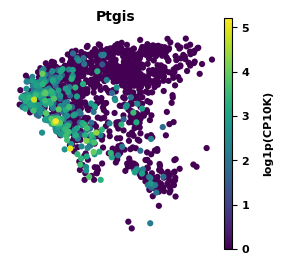

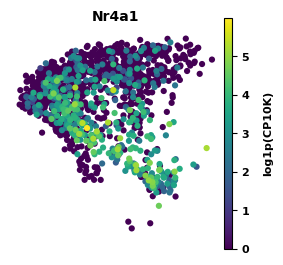

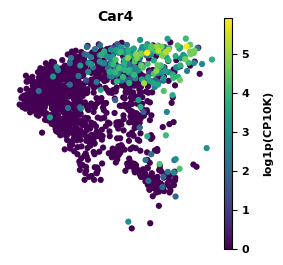

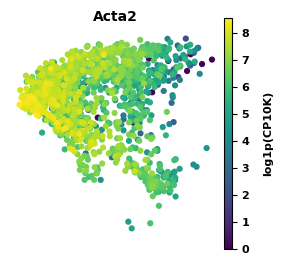

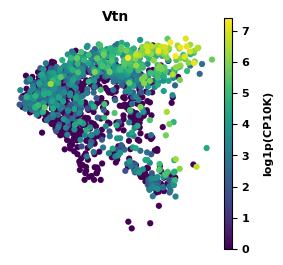

In [27]:
genes_to_plot_list = ["Ptgis",# "Atf5", 
                    "Nr4a1", #"Adamts1", #arterial
                        "Car4", #venous
                        "Acta2",  "Vtn",#"Myh11",  "Pdgfrb", # a.-v. gradient
                        ]
save_string_suffix = "smc"

plot_and_save_GE_ctrl_only(
    smc[smc_mask], 
    genes_to_plot_list, 
    f"{str(OUTDIR)}/", 
    save_string_suffix=save_string_suffix, 
    scattersize=s, 
    vmax=None)

## VLMC + Peri

In [28]:
vlmc = adata[(adata.obs.L2_descr.str.contains("VLMC") | adata.obs.L2_descr.str.contains("Peri"))].copy()

In [29]:
#plt.hist(vlmc.obsm["X_umap"][:, 1], bins=50)

In [30]:
#remove cells outside the main UMAP clusters
vlmc_mask = (vlmc.obsm["X_umap"][:, 1] > 12) & (
    vlmc.obsm["X_umap"][:, 0] >1.5) & (vlmc.obsm["X_umap"][:, 0] < 14)

In [31]:
vlmc_zoom = vlmc[vlmc_mask].copy()

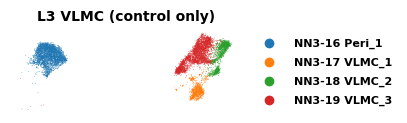

In [32]:
for i in range(3,4):

    fig, ax = plt.subplots(figsize=(3, 3), ) 
    sc.pl.umap(vlmc_zoom, color=f"L{i}_descr", ax=ax, s=1, show=False,  )

    # Rasterize only the scatter points (not text)
    for coll in ax.collections:
        coll.set_rasterized(True)

    # Customize: remove title, borders, ticks, labels
    ax.set_title(f"L{i} VLMC (control only)", fontweight="bold", fontsize=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect('equal')


    # --- Customize legend ---
    leg = ax.get_legend()
    if leg is not None:
        # Change font size and weight
        for text in leg.get_texts():
            text.set_fontsize(8)
            text.set_fontweight("bold")
        

    fig.canvas.draw()

    plt.savefig(OUTDIR /  f"5d_umap_L{i}_vlmc_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
    #plt.show()

In [33]:
vlmc

AnnData object with n_obs × n_vars = 10319 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like', 'L1_NN', 'L2_NN'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'log1p', 'L1_NN_colors'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

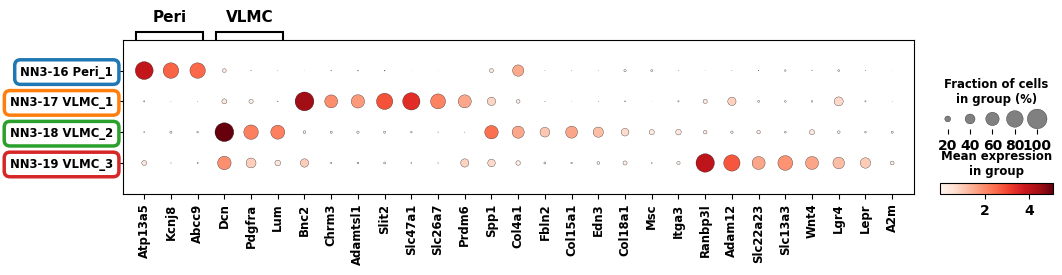

In [34]:

# -------------------
# Define genes and groups
# -------------------
vlmc_markers_list = [

    "Atp13a5", "Kcnj8", "Abcc9", # PC zeisel https://pmc.ncbi.nlm.nih.gov/articles/PMC6086934/

    "Dcn", "Pdgfra", "Lum",  # VLMC zeisel https://pmc.ncbi.nlm.nih.gov/articles/PMC6086934/

    "Bnc2","Chrm3", "Adamtsl1", "Slit2", "Slc47a1", "Slc26a7",  "Prdm6",

    "Spp1", "Col4a1","Fbln2", "Col15a1", "Edn3", "Col18a1", "Msc",  "Itga3", 

    "Ranbp3l", "Adam12","Slc22a23", "Slc13a3", "Wnt4",  "Lgr4", "Lepr", "A2m",  

]

# -------------------
# Define group positions
# -------------------
# Note: positions are 0-based index positions in mg_genes
var_group_positions = [
    (0, 2, "Peri"),
    (3, 5, "VLMC"),  
    #(6, 13, "N3-33"), 
    #(14, 21, "N3-34"),
    #(22, 29, "N3-35"),
]

# -------------------
# Compute figure size
# -------------------
total_height = 0.5 * len(vlmc.obs.L3_descr.unique())

# -------------------
# Create DotPlot
# -------------------
dotplot_obj = sc.pl.DotPlot(
    vlmc[vlmc.obs.IsControl],
    var_names=vlmc_markers_list,
    groupby="L3_descr",
    var_group_positions=[(start, end) for start, end, _ in var_group_positions],
    var_group_labels=[label for _, _, label in var_group_positions],
    var_group_rotation=0,
    figsize=(12, total_height),
    cmap="Reds",
    #standard_scale="var",  # optional normalization per gene
)

# Build the figure
dotplot_obj.make_figure()

# -------------------
# Customize axes and labels
# -------------------
ax = dotplot_obj.ax_dict['mainplot_ax']

# Make gene and group labels bold and add colored boxes
for i, label in enumerate(ax.get_yticklabels()):
    label.set_fontweight('bold')
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

# Color boxes around y-tick labels by cluster color
if "L3_descr_colors" in vlmc_zoom.uns: # the other object
    colors = vlmc_zoom.uns["L3_descr_colors"]
    for i, label in enumerate(ax.get_yticklabels()):
        color = colors[i % len(colors)]
        label.set_bbox(dict(facecolor="white", edgecolor=color,
                            boxstyle='round,pad=0.5', linewidth=2.5))

# -------------------
# Colorbar and legends
# -------------------
cbar_ax = dotplot_obj.fig.axes[-1]
for txt_obj in cbar_ax.texts + cbar_ax.get_yticklabels() + cbar_ax.get_xticklabels():
    txt_obj.set_fontweight('bold')
    txt_obj.set_fontsize(10)

if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontweight='bold')
if cbar_ax.get_xlabel():
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontweight='bold')

for text in cbar_ax.texts:
    text.set_fontweight('bold')

size_legend_ax = dotplot_obj.ax_dict['size_legend_ax']
for tick in size_legend_ax.get_xticklabels() + size_legend_ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make "expression"/"fraction" text bold
for text_obj in dotplot_obj.fig.findobj(match=plt.Text):
    txt = text_obj.get_text().lower()
    if "expression" in txt or "fraction" in txt:
        text_obj.set_fontweight('bold')
    if txt in ["20", "40", "60", "80", "100"]:
        text_obj.set_fontsize(10)

# Make var_group_labels (like "MG", "Inflam.") bold
for ax_name, ax in dotplot_obj.ax_dict.items():
    if "group" in ax_name:  # these axes hold the var_group labels
        for text_obj in ax.texts:
            text_obj.set_fontweight('bold')
            text_obj.set_fontsize(11)  # optional, adjust for clarity


# -------------------
# Save and show
# -------------------
plt.savefig(OUTDIR / "5e_dotplot_L3_PC_VLMC.pdf", dpi=300, format="pdf", bbox_inches="tight")
plt.show()
